# Урок 13. Как объёмное облачко оставляет пятно на экране

[Программа курса](../../README_ru.md)

С центральной точкой всё просто. Глубина 4 м, смещение вправо 1 м, фокус 80 пикселей — центр попадёт на 20 пикселей правее середины кадра. Но по обе стороны от него есть другие части того же облачка. Ближняя часть кажется крупнее дальней. Какую ширину тогда дать всему пятну?

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. Два рисунка поверх друг друга

Оранжевая сетка — оболочка одного масштаба из прошлого урока. Каждая вершина сетки получает координаты пикселя через собственное деление на глубину. Синий эллипс получается быстрее. Только у центра вычисляется, как сильно камера растягивает малые смещения; это растяжение затем применяется ко всей форме. Чёрная точка — проекция центра в обоих расчётах.

Пока центр далеко и облачко тонкое вдоль глубины, края двух рисунков почти сходятся. Если приблизить центр или вытянуть облачко вдоль $z$, ближний край оранжевой сетки начинает убегать. Ползунок ракурса обводит камеру вокруг неподвижной формы так, чтобы в системе камеры у центра оставались $(1,0,z)$. Меняется сторона, с которой видна длинная ось. Чёрная точка при таком повороте остаётся на месте.

In [2]:
display(demos.geometry_lab(13, "ru"))

## 2. Сколько пикселей даёт сантиметр

По горизонтали формула знакома: $u=100+80x/z$. У центра $(1,0,4)$ получаем $u=120$ px. Сдвинем точку вправо на $0.01$ м, не меняя глубины. Новое значение $100+80\cdot1.01/4=120.2$. Смещение на экране $0.2$ px, то есть $0.2/0.01=20$ пикселей на метр. Вертикальное смещение по $y$ горизонтальный адрес вообще не меняет.

Пусть тот же сантиметр теперь уходит вперёд, по $z$. Получится $100+80/4.01\approx119.950125$ px. Разность $-0.049875$ px за 0.01 м даёт примерно $-4.9875$ px/м. Минус имеет видимый смысл: дальняя точка подходит ближе к середине кадра. Какое число получится у самого центра, если сантиметр постепенно уменьшать? Обозначим шаг буквой $h$, а фокус через $f_x$. Главная точка исчезает при вычитании:

$$
\begin{aligned}
\frac{u(z+h)-u(z)}{h}
&=\frac{f_x x}{h}\left(\frac{1}{z+h}-\frac{1}{z}\right)\\
&=\frac{f_x x}{h}\frac{z-(z+h)}{z(z+h)}
=-\frac{f_x x}{z(z+h)}.
\end{aligned}
$$

Мы привели дроби к общему знаменателю, получили в числителе $-h$ и сократили ненулевой шаг. При уменьшении $h$ произведение внизу стремится к $z^2$. Местный отклик равен $-f_x x/z^2=-80\cdot1/16=-5$ px/м. Для положительного $x$ он отрицателен, для точки точно на оси с $x=0$ равен нулю.

In [3]:
mu = np.array([1., 0., 4.])
focal, principal = 80., (100., 60.)
uv = geo.project_point(mu, focal, principal)
for h in [.1, .01, .001]:
    moved = geo.project_point(mu+[0,0,h], focal, principal)
    print(f"h={h:g} m; Δu/h = {(moved[0]-uv[0])/h:.6f} px/m")

h=0.1 m; Δu/h = -4.878049 px/m
h=0.01 m; Δu/h = -4.987531 px/m
h=0.001 m; Δu/h = -4.998750 px/m


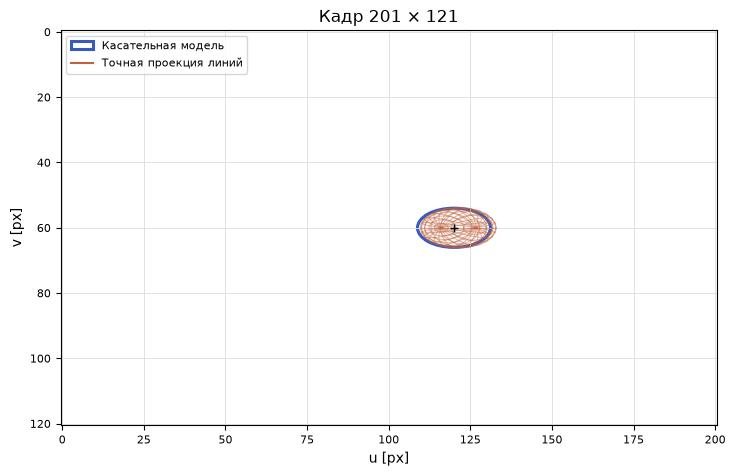

In [4]:
fig = demos.footprint_figure("ru")
plt.show()

## 3. Шесть откликов в одной таблице

У картинки два числа, $u$ и $v$. У смещения в пространстве три, $\Delta x,\Delta y,\Delta z$. Для каждой пары «ответ — причина» есть местный коэффициент. В таблице $J$ строки соответствуют экранным координатам, столбцы — пространственным. Такая таблица частных производных называется **якобианом**. «Частная» означает, что для одного столбца сдвигается только одна координата.

$$
J=
\begin{bmatrix}
f_x/z & 0 & -f_x x/z^2\\
0 & f_y/z & -f_y y/z^2
\end{bmatrix}
=\begin{bmatrix}20&0&-5\\0&20&0\end{bmatrix}.
$$

Здесь $y=0$, поэтому продвижение строго вперёд не меняет $v$. Для смещения $(0.1,0.05,0.2)$ м перемножим первую строку со столбцом: $20\cdot0.1+0\cdot0.05-5\cdot0.2=1$ px. Во второй строке $20\cdot0.05=1$ px. Прибавим к центру $(120,60)$, получим $(121,61)$ px. Точное деление для новой точки $(1.1,0.05,4.2)$ даёт $(120.9524,60.9524)$ px. Меньшее смещение оставит меньшую разницу.

Если шаг вдоль глубины целый метр, якобиан предскажет $120-5=115$ px. Точная точка на глубине 5 м даёт $100+80/5=116$ px. На метр **к** камере прогноз $120+5=125$ px, но точный результат $100+80/3\approx126.667$ px. У прямой одинаковый наклон на обеих сторонах; у перспективного деления наклон меняется по пути.

In [5]:
J = geo.projection_jacobian(mu, focal)
for delta in [[.1,.05,.2],[0,0,1],[0,0,-1]]:
    linear = uv + J @ delta
    exact = geo.project_point(mu+delta, focal, principal)
    print("Δ =", delta, "  linear =", linear, "  exact =", exact)

Δ = [0.1, 0.05, 0.2]   linear = [121.  61.]   exact = [120.9524  60.9524]
Δ = [0, 0, 1]   linear = [115.  60.]   exact = [116.  60.]
Δ = [0, 0, -1]   linear = [125.  60.]   exact = [126.6667  60.    ]


## 4. Как шесть чисел превращают объём в эллипс

В исходном положении ковариация облачка в системе камеры $\Sigma_c=\mathrm{diag}(0.25,0.09,1)$ м². Числа получились из масштабов $0.5$, $0.3$, $1$ м после возведения в квадрат. Для перемещения по экрану работают коэффициенты $J$. Для двух экранных направлений должны преобразоваться обе стороны ковариации:

$$
\Sigma_2=J\Sigma_c J^{\mathsf T}.
$$

Это прежнее правило «умножение с двух сторон», только теперь между тремя входными и двумя выходными осями. Его можно собрать на пальцах. Вдоль $u$ собственное смещение по $x$ величиной 0.5 м даёт масштаб $20\cdot0.5=10$ px. По $z$ один метр даёт $-5\cdot1=-5$ px. Независимые направления складывают **квадраты** вкладов: $10^2+(-5)^2=125$ px². Чтобы вернуться к длине, берём квадратный корень: $\sqrt{125}\approx11.180$ px. По $v$ действует только $y$: $20\cdot0.3=6$ px, квадрат равен 36 px².

Одна исходная ось должна влиять сразу на $u$ и $v$, чтобы появился перекрёстный вклад. Здесь у $u$ работают $x,z$, у $v$ — только $y$. Поэтому перекрёстный член равен нулю, и итоговая матрица — $\mathrm{diag}(125,36)$. При нулевом ракурсе «Поворот формы» на $45^\circ$ разворачивает длинную и короткую оси на экране. Их поперечные ковариации теперь равны $(0.25-0.09)/2=0.08$ м². Каждая экранная ось увеличивает смещения в 20 раз. Получается $\Sigma_{uv}=20\cdot0.08\cdot20=32$ px². Синий эллипс наклоняется вправо вниз. Матрица $2\times2$ и центр — уже знакомое пятно из урока 4.

А если начальная форма задана в мире? Ориентация камеры $B$ из урока 10 переносит её оси в мир. Из мира **в камеру** смещения преобразуются матрицей $W=B^{\mathsf T}$. Сначала $\Sigma_c=W\Sigma_w W^{\mathsf T}$, затем уже применяется $J$. Перенос центра камеры исчезает для разностей соседних точек, но остаётся в положении центра, от которого зависит сам $J$. В [статье Kerbl и соавторов](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) эти два шага объединены. Здесь мы оставили их раздельными, чтобы видеть, в каких единицах живёт каждая матрица.

In [6]:
cov3 = geo.covariance_3d([.5,.3,1], [1,0,0,0])
cov2 = geo.projected_covariance(mu, cov3, focal)
print("J =\n", J, "\nΣ₂ =\n", cov2, "\nradii =", np.sqrt(np.diag(cov2)), "px")
np.testing.assert_allclose(cov2, np.diag([125,36]))
tilted = geo.covariance_3d([.5,.3,1], geo.axis_angle_quaternion([0,0,1],45))
np.testing.assert_allclose(geo.projected_covariance(mu, tilted, focal), [[93,32],[32,68]])

J =
 [[20.  0. -5.]
 [ 0. 20. -0.]] 
Σ₂ =
 [[125.   0.]
 [  0.  36.]] 
radii = [11.1803  6.    ] px


## 5. Где синий контур перестаёт успевать

В опыте у ближней плоскости глубина 0.2 м. Пусть у центра $z=2$, а масштаб вдоль глубины 1.5 м. Ближний конец оболочки находится на $2-1.5=0.5$ м. Даже самая ближняя часть ещё перед камерой, но разница между делением на 0.5 и на 2 уже огромна. На рисунке остаётся только часть оранжевой сетки, помещающаяся внутри кадра.

Если опустить глубину центра до 1 м при том же размере, часть поверхности пересечёт плоскость отсечения. Такие точки исключаются из оранжевой сетки. Для центра всё ещё существует якобиан и можно нарисовать синий эллипс. Вычислить эллипс оказалось проще, чем оправдать точность его формы. Кроме того, у самой гауссианы есть бесконечные хвосты; опыт сравнивает выбранную оболочку $D^2=1$, а не интеграл света вдоль луча или точную проекцию всей плотности.

**Опыт.** Центр переместился на оптическую ось в $(0,0,4)$. Изменится ли синий эллипс при удвоении только $s_z$, если собственные оси и камера совпадают?

<details>
<summary>Разбор</summary>

Оба коэффициента глубины равны нулю: $-80\cdot0/16=0$. Значит, внутри линейной модели вклад $s_z$ исчез. Радиусы равны $20\cdot0.5=10$ и $20\cdot0.3=6$ px. Оранжевая сетка при утолщении всё равно изменится, потому что точки вдали от центра имеют свои $x,y,z$.

</details>

**Оценка ошибки.** Насколько ошибётся горизонтальный прогноз для точки на 0.5 м ближе исходного центра $(1,0,4)$?

<details>
<summary>Разбор</summary>

Шаг $\Delta z=-0.5$. Якобиан предсказывает $120+(-5)(-0.5)=122.5$ px. Точное деление даёт $100+80/3.5\approx122.857$ px. Разница примерно 0.357 px. Дальше в сцене таких пятен будет несколько, и к вопросу об их форме добавится вопрос об очерёдности смешивания.

</details>

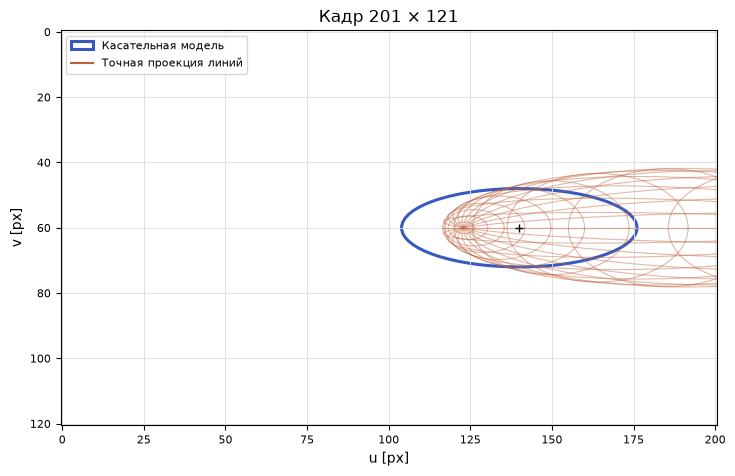

In [7]:
fig = demos.footprint_figure("ru", depth=2, sz=1.5)
plt.show()